In [6]:
import pandas as pd
from sklearn.datasets import load_diabetes

# Load the built-in clinical diabetes dataset directly into a DataFrame
data = load_diabetes(as_frame=True)
df = data.frame

# Print the first 5 patient rows
print(df.head())


        age       sex       bmi        bp        s1        s2        s3  \
0  0.038076  0.050680  0.061696  0.021872 -0.044223 -0.034821 -0.043401   
1 -0.001882 -0.044642 -0.051474 -0.026328 -0.008449 -0.019163  0.074412   
2  0.085299  0.050680  0.044451 -0.005670 -0.045599 -0.034194 -0.032356   
3 -0.089063 -0.044642 -0.011595 -0.036656  0.012191  0.024991 -0.036038   
4  0.005383 -0.044642 -0.036385  0.021872  0.003935  0.015596  0.008142   

         s4        s5        s6  target  
0 -0.002592  0.019907 -0.017646   151.0  
1 -0.039493 -0.068332 -0.092204    75.0  
2 -0.002592  0.002861 -0.025930   141.0  
3  0.034309  0.022688 -0.009362   206.0  
4 -0.002592 -0.031988 -0.046641   135.0  


In [7]:
# 1. Check total number of patients (rows) and medical metrics (columns)
print("Dataset Shape (Rows, Columns):", df.shape)

# 2. Check every column for missing or blank values
print("\nMissing Values per Column:")
print(df.isna().sum())

# 3. Calculate key clinical averages (mean, min, max) across all patients
print("\nClinical Summary Statistics:")
print(df.describe())


Dataset Shape (Rows, Columns): (442, 11)

Missing Values per Column:
age       0
sex       0
bmi       0
bp        0
s1        0
s2        0
s3        0
s4        0
s5        0
s6        0
target    0
dtype: int64

Clinical Summary Statistics:
                age           sex           bmi            bp            s1  \
count  4.420000e+02  4.420000e+02  4.420000e+02  4.420000e+02  4.420000e+02   
mean  -2.511817e-19  1.230790e-17 -2.245564e-16 -4.797570e-17 -1.381499e-17   
std    4.761905e-02  4.761905e-02  4.761905e-02  4.761905e-02  4.761905e-02   
min   -1.072256e-01 -4.464164e-02 -9.027530e-02 -1.123988e-01 -1.267807e-01   
25%   -3.729927e-02 -4.464164e-02 -3.422907e-02 -3.665608e-02 -3.424784e-02   
50%    5.383060e-03 -4.464164e-02 -7.283766e-03 -5.670422e-03 -4.320866e-03   
75%    3.807591e-02  5.068012e-02  3.124802e-02  3.564379e-02  2.835801e-02   
max    1.107267e-01  5.068012e-02  1.705552e-01  1.320436e-01  1.539137e-01   

                 s2            s3           

Number of High-Risk Patients: 121


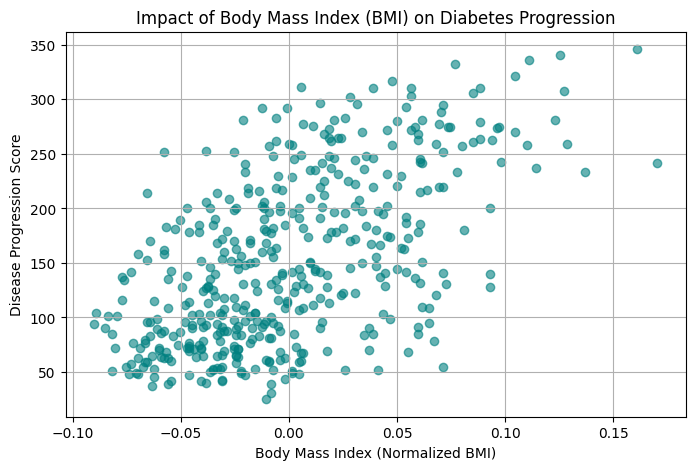

In [8]:
import matplotlib.pyplot as plt

# 1. Filter patients with high disease progression (target > 200)
high_risk = df[df['target'] > 200]
print("Number of High-Risk Patients:", len(high_risk))

# 2. Plot a scatter chart comparing Body Mass Index (bmi) vs Disease Progression (target)
plt.figure(figsize=(8, 5))
plt.scatter(df['bmi'], df['target'], color='teal', alpha=0.6)
plt.title("Impact of Body Mass Index (BMI) on Diabetes Progression")
plt.xlabel("Body Mass Index (Normalized BMI)")
plt.ylabel("Disease Progression Score")
plt.grid(True)
plt.show()


In [9]:
# 1. Calculate exact correlation of all medical metrics with Diabetes Progression
correlations = df.corr()['target'].sort_values(ascending=False)
print("--- Correlation with Disease Progression (1.0 = Strongest) ---")
print(correlations)

# 2. Segment patients into Clinical Risk Tiers
def assign_risk_tier(score):
    if score < 100:
        return "Low Risk"
    elif score <= 200:
        return "Moderate Risk"
    else:
        return "High Risk"

df['Risk_Tier'] = df['target'].apply(assign_risk_tier)
print("\n--- Patient Count by Clinical Risk Tier ---")
print(df['Risk_Tier'].value_counts())

# 3. Comorbidity Analysis: High BMI (> 0.05) AND High Blood Pressure (> 0.05)
comorbid_patients = df[(df['bmi'] > 0.05) & (df['bp'] > 0.05)]
print("\nHigh-BMI + High-BP Comorbid Patients:", len(comorbid_patients))
print("Average Disease Progression for Comorbid Group:", round(comorbid_patients['target'].mean(), 2))
print("Average Disease Progression for Overall Population:", round(df['target'].mean(), 2))


--- Correlation with Disease Progression (1.0 = Strongest) ---
target    1.000000
bmi       0.586450
s5        0.565883
bp        0.441482
s4        0.430453
s6        0.382483
s1        0.212022
age       0.187889
s2        0.174054
sex       0.043062
s3       -0.394789
Name: target, dtype: float64

--- Patient Count by Clinical Risk Tier ---
Risk_Tier
Moderate Risk    174
Low Risk         147
High Risk        121
Name: count, dtype: int64

High-BMI + High-BP Comorbid Patients: 31
Average Disease Progression for Comorbid Group: 261.55
Average Disease Progression for Overall Population: 152.13


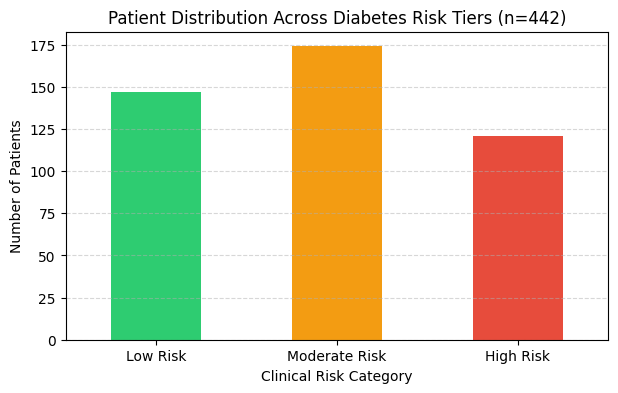

In [10]:
# Plot a color-coded bar chart of Patient Risk Tiers
tier_counts = df['Risk_Tier'].value_counts().reindex(["Low Risk", "Moderate Risk", "High Risk"])

plt.figure(figsize=(7, 4))
tier_counts.plot(kind='bar', color=['#2ecc71', '#f39c12', '#e74c3c'])
plt.title("Patient Distribution Across Diabetes Risk Tiers (n=442)")
plt.xlabel("Clinical Risk Category")
plt.ylabel("Number of Patients")
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.5)

# Save the chart directly as an image file for your GitHub!
plt.savefig("diabetes_risk_tiers.png", dpi=300, bbox_inches='tight')
plt.show()
